In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
import torch, torchvision; print(torch.__version__, torchvision.__version__)

name, memory.total [MiB]
NVIDIA A100-SXM4-40GB, 40960 MiB
2.14.1+cu130 0.29.1+cu130


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
DIR = '/content/drive/MyDrive/dl_kaggle'
!cp "$DIR/data.zip" "$DIR/train.py" /content/
%cd /content

Mounted at /content/drive
/content


## 1. Smoke test (~1 min): checks data loading, parameter count, training loop and submission writing

In [ ]:
!python train.py --data data.zip --smoke --out "$DIR/runs/smoke"
!head -3 "$DIR/runs/smoke/submission.csv"

/content/train.py:294: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=not use_bf16)
device: NVIDIA A100-SXM4-40GB | AMP torch.bfloat16
decoded 50000 train / 2000 test images in 11s
train 512 | val 256 | test 128
trainable parameters: 4,941,898  (limit 5,000,000)
epoch 1 | lr 0.2000 | train_loss 1.3427 | train_acc 0.8750 | epoch_time_s 9.8318 | val_acc 1.0000 | val_acc_ema 1.0000
epoch 2 | lr 0.0000 | train_loss 1.2493 | train_acc 1.0000 | epoch_time_s 0.3528 | val_acc 1.0000 | val_acc_ema 1.0000
{
  "n_params": 4941898,
  "train_time_min": 0.17857505480448405,
  "val_acc_raw": 1.0,
  "val_acc_raw_tta": 1.0,
  "val_acc_ema": 1.0,
  "val_acc_ema_tta": 1.0,
  "final_weights": "raw",
  "test_pred_class_counts": [
    128,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0,
    0
  ]
}
wrote /content/drive/MyDrive/dl_kaggle/runs/smoke/submission.csv
id,label
0,0
1

## 2. Validation run: 45k train / 5k val, 200 epochs
Use this to compare recipes. Expect the Kaggle score to be several points **below** this val accuracy: the hidden test set is a separately collected CIFAR-style set, not the standard CIFAR-10 test split.

In [ ]:
!python train.py --data data.zip --val_size 5000 --epochs 200 --out "$DIR/runs/val_e200"

/content/train.py:294: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=not use_bf16)
device: NVIDIA A100-SXM4-40GB | AMP torch.bfloat16
train 45000 | val 5000 | test 2000
trainable parameters: 4,941,898  (limit 5,000,000)
epoch 1 | lr 0.0402 | train_loss 2.1760 | train_acc 0.2066 | epoch_time_s 8.9414 | val_acc 0.3198 | val_acc_ema 0.3182
epoch 2 | lr 0.0802 | train_loss 2.0700 | train_acc 0.2576 | epoch_time_s 4.0494 | val_acc 0.3148 | val_acc_ema 0.3716
epoch 3 | lr 0.1202 | train_loss 1.9604 | train_acc 0.3147 | epoch_time_s 3.9834
epoch 4 | lr 0.1602 | train_loss 1.8460 | train_acc 0.3721 | epoch_time_s 4.0353
epoch 5 | lr 0.2000 | train_loss 1.7477 | train_acc 0.4267 | epoch_time_s 4.0436 | val_acc 0.5708 | val_acc_ema 0.6162
epoch 6 | lr 0.2000 | train_loss 1.6576 | train_acc 0.4699 | epoch_time_s 3.9751
epoch 7 | lr 0.1999 | train_loss 1.5799 | train_acc 0.

## 3. Final run: all 50k images → `submission.csv`

In [ ]:
!python train.py --data data.zip --val_size 0 --epochs 200 --out "$DIR/runs/full_e200"

/content/train.py:294: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=not use_bf16)
device: NVIDIA A100-SXM4-40GB | AMP torch.bfloat16
train 50000 | val 0 | test 2000
trainable parameters: 4,941,898  (limit 5,000,000)
epoch 1 | lr 0.0402 | train_loss 2.1708 | train_acc 0.2078 | epoch_time_s 9.4854
epoch 2 | lr 0.0802 | train_loss 2.0612 | train_acc 0.2634 | epoch_time_s 4.3966
epoch 3 | lr 0.1202 | train_loss 1.9388 | train_acc 0.3226 | epoch_time_s 4.4115
epoch 4 | lr 0.1602 | train_loss 1.8143 | train_acc 0.3900 | epoch_time_s 4.5055
epoch 5 | lr 0.2000 | train_loss 1.7123 | train_acc 0.4475 | epoch_time_s 4.3419
epoch 6 | lr 0.2000 | train_loss 1.6489 | train_acc 0.4761 | epoch_time_s 4.3541
epoch 7 | lr 0.1999 | train_loss 1.5715 | train_acc 0.5150 | epoch_time_s 4.4686
epoch 8 | lr 0.1999 | train_loss 1.5191 | train_acc 0.5431 | epoch_time_s 4.3529
epoch 9 |

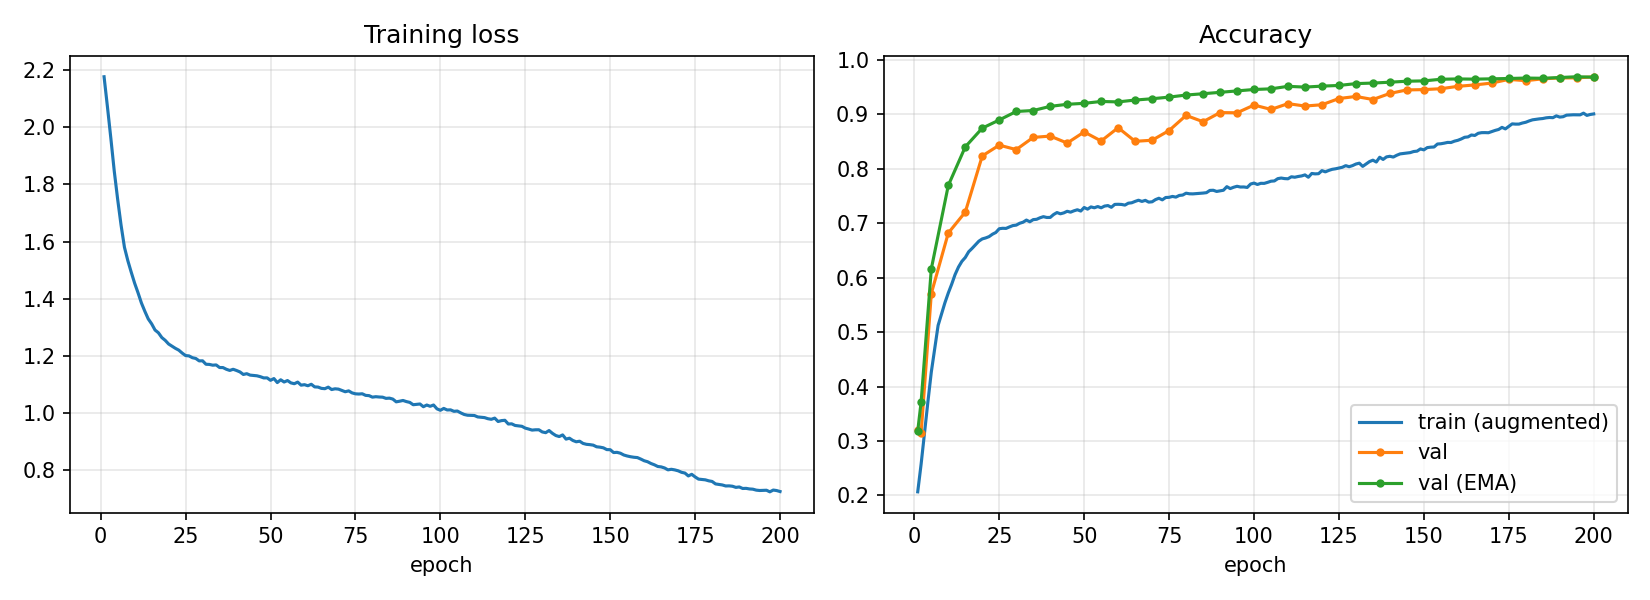

{
  "n_params": 4941898,
  "train_time_min": 13.540051666895549,
  "val_acc_raw": 0.9688,
  "val_acc_raw_tta": 0.9716,
  "val_acc_ema": 0.9682,
  "val_acc_ema_tta": 0.9714,
  "final_weights": "raw",
  "test_pred_class_counts": [
    172,
    217,
    202,
    199,
    190,
    221,
    181,
    205,
    206,
    207
  ]
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from IPython.display import Image, display
import json
display(Image(f'{DIR}/runs/val_e200/curves.png'))
print(json.dumps(json.load(open(f'{DIR}/runs/val_e200/summary.json')), indent=2))
from google.colab import files
files.download(f'{DIR}/runs/full_e200/submission.csv')

In [ ]:
!python train.py --data data.zip --val_size 0 --epochs 400 --out "$DIR/runs/full_e400"
!python train.py --data data.zip --val_size 0 --epochs 200 --gray 0.1 --jitter 0.3 --out "$DIR/runs/full_e200_color"
!python train.py --data data.zip --val_size 0 --epochs 400 --gray 0.1 --jitter 0.3 --cutmix 0.5 --out "$DIR/runs/full_e400_color_cutmix"

device: NVIDIA A100-SXM4-40GB | AMP torch.bfloat16
train 50000 | val 0 | test 2000
trainable parameters: 4,941,898  (limit 5,000,000)
epoch 1 | lr 0.0402 | train_loss 2.1714 | train_acc 0.2052 | epoch_time_s 9.4422
epoch 2 | lr 0.0802 | train_loss 2.0604 | train_acc 0.2638 | epoch_time_s 4.5134
epoch 3 | lr 0.1202 | train_loss 1.9351 | train_acc 0.3244 | epoch_time_s 4.5693
epoch 4 | lr 0.1602 | train_loss 1.8132 | train_acc 0.3929 | epoch_time_s 4.4826
epoch 5 | lr 0.2000 | train_loss 1.7164 | train_acc 0.4425 | epoch_time_s 4.5944
epoch 6 | lr 0.2000 | train_loss 1.6376 | train_acc 0.4822 | epoch_time_s 4.5554
epoch 7 | lr 0.2000 | train_loss 1.5615 | train_acc 0.5199 | epoch_time_s 4.6407
epoch 8 | lr 0.2000 | train_loss 1.5093 | train_acc 0.5458 | epoch_time_s 4.6777
epoch 9 | lr 0.1999 | train_loss 1.4663 | train_acc 0.5650 | epoch_time_s 4.5352
epoch 10 | lr 0.1999 | train_loss 1.4327 | train_acc 0.5802 | epoch_time_s 4.4769
epoch 11 | lr 0.1999 | train_loss 1.3879 | train_acc 0.

In [ ]:
   !cp "$DIR/train.py" /content/train.py
   !grep -c "gray" /content/train.py

5


In [ ]:
!grep -c "teachers" /content/train.py

6


In [ ]:
!python train.py --data data.zip --val_size 0 --epochs 200 --arch wrn --depth 28 --widen 10 --teacher_only --gray 0.1 --jitter 0.3 --cutmix 0.5 --out "$DIR/runs/teacher_wrn28_10"
!python train.py --data data.zip --val_size 0 --epochs 400 --gray 0.1 --jitter 0.3 --cutmix 0.5 --teachers "$DIR/runs/teacher_wrn28_10/model.pt" "$DIR/runs/full_e400_color_cutmix/model.pt" "$DIR/runs/full_e200_color/model.pt" "$DIR/runs/full_e400/model.pt" --out "$DIR/runs/kd_e400"

device: NVIDIA L4 | AMP torch.bfloat16
decoded 50000 train / 2000 test images in 10s
train 50000 | val 0 | test 2000
trainable parameters: 36,479,194  (limit 5,000,000)
teacher_only: training a KD teacher; no submission will be written
epoch 1 | lr 0.0402 | train_loss 2.1695 | train_acc 0.2112 | epoch_time_s 55.5370
epoch 2 | lr 0.0802 | train_loss 1.9766 | train_acc 0.3263 | epoch_time_s 45.6983
epoch 3 | lr 0.1202 | train_loss 1.8703 | train_acc 0.3867 | epoch_time_s 46.1997
epoch 4 | lr 0.1602 | train_loss 1.7999 | train_acc 0.4316 | epoch_time_s 46.5708
epoch 5 | lr 0.2000 | train_loss 1.7399 | train_acc 0.4608 | epoch_time_s 46.9427
epoch 6 | lr 0.2000 | train_loss 1.7093 | train_acc 0.4783 | epoch_time_s 46.9784
epoch 7 | lr 0.1999 | train_loss 1.6572 | train_acc 0.4974 | epoch_time_s 46.9389
epoch 8 | lr 0.1999 | train_loss 1.6112 | train_acc 0.5234 | epoch_time_s 46.9505
epoch 9 | lr 0.1998 | train_loss 1.6125 | train_acc 0.5204 | epoch_time_s 46.8085
epoch 10 | lr 0.1997 | tra

In [ ]:
!grep -c "teachers" /content/train.py

6


In [ ]:
!nohup python train.py --data data.zip --val_size 0 --epochs 600 --gray 0.2 --jitter 0.4 --cutmix 0.5 --out "$DIR/runs/full_e600_color2_cutmix" > /content/e600.log 2>&1 &

In [ ]:
!tail -n 3 /content/e600.log

  ]
}
done: outputs in /content/drive/MyDrive/dl_kaggle/runs/full_e600_color2_cutmix


In [ ]:
!cp "$DIR/predict.py" /content/
!python predict.py --model "$DIR/runs/full_e400_color_cutmix/model.pt" --out "$DIR/runs/full_e400_color_cutmix/submission_tta.csv"

trainable parameters: 4,941,898  (limit 5,000,000)
views per image: 18
agreement with flip-only predictions: 0.9690 (62 images changed)
predicted class counts: [174, 226, 215, 193, 199, 210, 182, 204, 201, 196]
wrote /content/drive/MyDrive/dl_kaggle/runs/full_e400_color_cutmix/submission_tta.csv
